## Step 1 — Install required packages


In [1]:
%pip install -U pandas numpy matplotlib seaborn scikit-learn imbalanced-learn statsmodels scipy joblib optuna lightgbm xgboost

Note: you may need to restart the kernel to use updated packages.


## Step 2 — Import Libraries & Define Configuration

In [2]:
from pathlib import Path
import warnings, json, math, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.stats import skew
from scipy.stats import boxcox
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC, ADASYN
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_SEED = 42
DROP_MISSING_THRESHOLD = 0.70  # assignment asks to drop columns with >=70% missing
SKEW_THRESHOLD = 1.0
WINSORIZE_LOW = 0.01
WINSORIZE_HIGH = 0.99
IV_THRESHOLD = 0.02
MAX_IV_THRESHOLD = 0.50
VIF_THRESHOLD = 10.0
CORR_THRESHOLD = 0.65
SMOTE_RATIO = 0.10  # minority / majority target ratio for optional resampling

from pathlib import Path

# Set the project directory explicitly
PROJECT_DIR = Path.home() / "Desktop" / "Hexaware_OA"

# Define project paths
DATA_PATH = PROJECT_DIR / "data" / "employee_attrition.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "saved_models"

# Create output folders inside the project
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Outputs directory:", OUTPUT_DIR.resolve())
print("Saved models directory:", MODEL_DIR.resolve())

# Verify that the dataset exists
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"


Project directory: /Users/riteshchaurasiya/Desktop/Hexaware_OA
Dataset path: /Users/riteshchaurasiya/Desktop/Hexaware_OA/data/employee_attrition.csv
Outputs directory: /Users/riteshchaurasiya/Desktop/Hexaware_OA/outputs
Saved models directory: /Users/riteshchaurasiya/Desktop/Hexaware_OA/saved_models


## Step 3 — Load data, inspect shape/types/columns and target

In [3]:
import pandas as pd

# Step 1: Load the dataset
file_path = "/Users/riteshchaurasiya/Desktop/Hexaware_OA/data/employee_attrition.csv"
df = pd.read_csv(file_path)

# Step 2: Display dataset information
print("Dataset Shape:", df.shape)

# Step 3: Display the first 5 rows
display(df.head())

# Step 4: Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 5: Check data types and missing values
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

# Step 6: Select the target column
TARGET = "attrition"

# Step 7: Check whether the target exists
if TARGET in df.columns:
    print("\nTarget column found:", TARGET)
else:
    print("\nTarget column not found!")

Dataset Shape: (500, 22)


,employee_id,age,gender,department,education,total_experience_yrs,tenure_yrs,monthly_salary_inr,last_hike_pct,performance_rating,...,projects_last_year,training_hours_last_year,commute_km,work_mode,manager_rating,job_satisfaction,promotion_last_2yrs,prev_companies,exit_interview_done,attrition
0,E1308,40,Male,Development,M.Tech,17.2,5.3,199300,6.7,5,...,4,29.0,25.7,Onsite,3.0,4,0,1,0,0
1,E1013,38,Female,Support,MCA,14.8,0.6,145400,13.4,4,...,5,53.0,27.5,Onsite,2.0,3,0,1,0,0
2,E1414,32,Male,Development,MCA,8.5,1.4,125900,9.2,3,...,5,18.0,4.8,Onsite,4.0,4,0,2,0,0
3,E1032,33,Female,Development,M.Tech,10.4,0.7,150400,4.3,2,...,2,23.0,11.1,Hybrid,3.0,3,0,4,1,1
4,E1460,39,Male,Data & AI,B.Tech,16.9,1.7,182100,12.0,4,...,4,43.0,21.0,Onsite,4.0,3,0,2,1,1



Column Names:
['employee_id', 'age', 'gender', 'department', 'education', 'total_experience_yrs', 'tenure_yrs', 'monthly_salary_inr', 'last_hike_pct', 'performance_rating', 'avg_weekly_hours', 'overtime_days_per_month', 'projects_last_year', 'training_hours_last_year', 'commute_km', 'work_mode', 'manager_rating', 'job_satisfaction', 'promotion_last_2yrs', 'prev_companies', 'exit_interview_done', 'attrition']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               500 non-null    str    
 1   age                       500 non-null    int64  
 2   gender                    500 non-null    str    
 3   department                500 non-null    str    
 4   education                 500 non-null    str    
 5   total_experience_yrs      500 non-null    float64
 6   tenure_yrs                

## Step 4 — Target class balance

,count,percentage
Negative / stayed (0),399,79.8
Positive / attrition (1),101,20.2


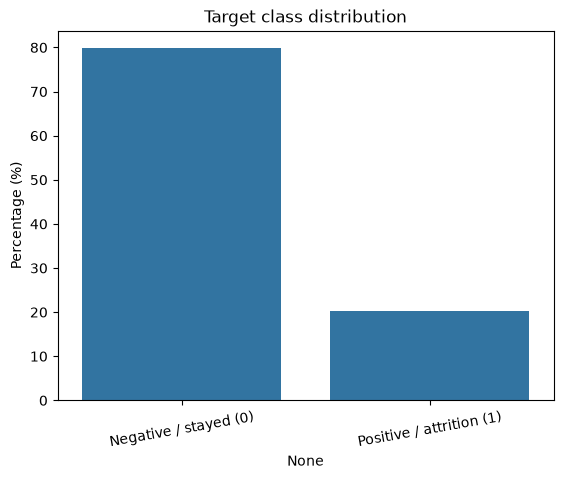

Minority class share: 20.2%
Per the stated rule, optional imbalance sampling is triggered only if minority share < 10%.


In [4]:
target_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
target_pct = (df[TARGET].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100).round(2)
target_summary = pd.DataFrame({"count": target_counts, "percentage": target_pct})
target_summary.index = ["Negative / stayed (0)", "Positive / attrition (1)"]
display(target_summary)

ax = sns.barplot(x=target_summary.index, y=target_summary["percentage"])
ax.set_title("Target class distribution")
ax.set_ylabel("Percentage (%)")
plt.xticks(rotation=10)
plt.show()

minority_share = min((df[TARGET] == 0).mean(), (df[TARGET] == 1).mean())
print(f"Minority class share: {minority_share:.1%}")
print("Per the stated rule, optional imbalance sampling is triggered only if minority share < 10%.")


## Step 5 — Split 80:20 

In [5]:
X_all = df.drop(columns=[TARGET]).copy()
y_all = df[TARGET].copy()

# Remove rows with a missing target above; stratify to preserve class proportions.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_SEED, stratify=y_all
)
print("Train:", X_train_raw.shape, "Test:", X_test_raw.shape)
print("Train target proportions:\n", y_train.value_counts(normalize=True).sort_index().round(3))
print("Test target proportions:\n", y_test.value_counts(normalize=True).sort_index().round(3))


Train: (400, 21) Test: (100, 21)
Train target proportions:
 attrition
0    0.798
1    0.202
Name: proportion, dtype: float64
Test target proportions:
 attrition
0    0.8
1    0.2
Name: proportion, dtype: float64


## Step 5B — Decide whether sampling is necessary

In [6]:
minority_train_share = min(y_train.mean(), 1 - y_train.mean())
DO_SAMPLING_BY_RULE = minority_train_share < 0.10
print(f"Training minority share: {minority_train_share:.1%}")
print("Sampling rule :", DO_SAMPLING_BY_RULE)


Training minority share: 20.2%
Sampling rule : False


## Step 6 — Missingness, duplicates and data quality audit

In [7]:
missing_audit = pd.DataFrame({
    "missing_count": X_train_raw.isna().sum(),
    "missing_pct": (X_train_raw.isna().mean() * 100).round(2),
    "dtype": X_train_raw.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)
display(missing_audit)

print("Duplicate full rows in source data:", int(df.duplicated().sum()))
print("Duplicate employee_id values:", int(df["employee_id"].duplicated().sum()) if "employee_id" in df else "n/a")

# Label consistency audit for categorical columns
for c in X_train_raw.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{c} unique labels:", sorted(X_train_raw[c].dropna().astype(str).str.strip().unique().tolist()))


,missing_count,missing_pct,dtype
manager_rating,23,5.75,float64
last_hike_pct,18,4.50,float64
training_hours_last_year,17,4.25,float64
commute_km,13,3.25,float64
employee_id,0,0.00,str
overtime_days_per_month,0,0.00,int64
prev_companies,0,0.00,int64
promotion_last_2yrs,0,0.00,int64
job_satisfaction,0,0.00,int64
work_mode,0,0.00,str


Duplicate full rows in source data: 2
Duplicate employee_id values: 2

employee_id unique labels: ['E1000', 'E1001', 'E1002', 'E1003', 'E1004', 'E1005', 'E1006', 'E1007', 'E1008', 'E1010', 'E1012', 'E1014', 'E1015', 'E1017', 'E1018', 'E1019', 'E1020', 'E1021', 'E1023', 'E1024', 'E1026', 'E1027', 'E1028', 'E1029', 'E1030', 'E1032', 'E1033', 'E1034', 'E1036', 'E1037', 'E1038', 'E1039', 'E1040', 'E1042', 'E1043', 'E1044', 'E1045', 'E1046', 'E1047', 'E1050', 'E1051', 'E1052', 'E1053', 'E1054', 'E1056', 'E1057', 'E1058', 'E1059', 'E1060', 'E1061', 'E1062', 'E1064', 'E1065', 'E1066', 'E1067', 'E1068', 'E1071', 'E1072', 'E1073', 'E1074', 'E1079', 'E1082', 'E1083', 'E1085', 'E1086', 'E1087', 'E1089', 'E1090', 'E1091', 'E1092', 'E1093', 'E1097', 'E1098', 'E1099', 'E1102', 'E1103', 'E1104', 'E1105', 'E1106', 'E1107', 'E1109', 'E1111', 'E1112', 'E1113', 'E1114', 'E1115', 'E1116', 'E1117', 'E1118', 'E1119', 'E1120', 'E1121', 'E1123', 'E1124', 'E1125', 'E1126', 'E1127', 'E1128', 'E1129', 'E1130', '

## Step 7–8 — Remove identifiers/leakage columns and high-missing columns

In [8]:
# Drop known PII/identifiers and post-outcome leakage.
PII_OR_ID_COLUMNS = [c for c in ["employee_id", "gender"] if c in X_train_raw.columns]  # gender retained only for fairness audit, not prediction
LEAKAGE_COLUMNS = [c for c in ["exit_interview_done"] if c in X_train_raw.columns]
missing_pct_train = X_train_raw.isna().mean()
HIGH_MISSING_COLUMNS = missing_pct_train[missing_pct_train >= DROP_MISSING_THRESHOLD].index.tolist()

DROP_COLUMNS = sorted(set(PII_OR_ID_COLUMNS + LEAKAGE_COLUMNS + HIGH_MISSING_COLUMNS))
print("Identifier/sensitive predictor columns dropped:", PII_OR_ID_COLUMNS)
print("Leakage columns dropped:", LEAKAGE_COLUMNS)
print(f"Columns with >= {DROP_MISSING_THRESHOLD:.0%} missing in TRAIN:", HIGH_MISSING_COLUMNS)
print("Total dropped:", DROP_COLUMNS)

X_train = X_train_raw.drop(columns=DROP_COLUMNS, errors="ignore").copy()
X_test = X_test_raw.drop(columns=DROP_COLUMNS, errors="ignore").copy()

# Normalize string labels without changing meaning.
for frame in (X_train, X_test):
    for c in frame.select_dtypes(include=["object", "category"]).columns:
        frame[c] = frame[c].astype("string").str.strip().replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Remove exact duplicate rows from training only; do not use test outcomes to make decisions.
train_combined = X_train.copy()
train_combined[TARGET] = y_train
dup_mask = train_combined.duplicated()
if dup_mask.any():
    print("Dropping duplicate training rows:", int(dup_mask.sum()))
    X_train = X_train.loc[~dup_mask].copy()
    y_train = y_train.loc[~dup_mask].copy()

print("Feature count after initial drops:", X_train.shape[1])


Identifier/sensitive predictor columns dropped: ['employee_id', 'gender']
Leakage columns dropped: ['exit_interview_done']
Columns with >= 70% missing in TRAIN: []
Total dropped: ['employee_id', 'exit_interview_done', 'gender']
Dropping duplicate training rows: 2
Feature count after initial drops: 18


## Step 9 — Imputation plan and basic logical checks
Imputers are fitted inside the modeling pipelines, so test data cannot influence their values.

In [9]:
# Review impossible/illogical values. Do not automatically delete valid outliers without domain justification.
display(X_train.describe(include="all").T)

logical_checks = {}
if {"total_experience_yrs", "tenure_yrs"}.issubset(X_train.columns):
    logical_checks["tenure_gt_total_experience"] = X_train["tenure_yrs"] > X_train["total_experience_yrs"]
if "age" in X_train.columns:
    logical_checks["age_outside_18_75"] = (X_train["age"] < 18) | (X_train["age"] > 75)
for name, mask in logical_checks.items():
    print(name, "count:", int(mask.fillna(False).sum()))

# Reusable column-type detector for each feature subset.
def get_feature_types(frame):
    numeric = frame.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical = [c for c in frame.columns if c not in numeric]
    return numeric, categorical

numeric_features, categorical_features = get_feature_types(X_train)
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,398.0,NaN,NaN,NaN,31.502513,5.744672,22.0,27.25,31.0,35.0,48.0
department,398,5,Development,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,398,4,B.Tech,255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_experience_yrs,398.0,NaN,NaN,NaN,8.671859,5.705008,0.0,4.525,8.4,12.475,27.1
tenure_yrs,398.0,NaN,NaN,NaN,3.070603,2.301027,0.1,1.3,2.8,4.3,12.4
monthly_salary_inr,398.0,NaN,NaN,NaN,120491.457286,108972.933008,20000.0,77650.0,107900.0,145900.0,1732000.0
last_hike_pct,380.0,NaN,NaN,NaN,8.615,3.494838,0.0,6.275,8.7,11.0,19.1
performance_rating,398.0,NaN,NaN,NaN,3.276382,0.941083,1.0,3.0,3.0,4.0,5.0
avg_weekly_hours,398.0,NaN,NaN,NaN,44.293719,6.612608,32.0,40.0,44.35,48.175,110.0
overtime_days_per_month,398.0,NaN,NaN,NaN,3.781407,2.111491,0.0,2.0,4.0,5.0,11.0


tenure_gt_total_experience count: 25
age_outside_18_75 count: 0
Numeric: ['age', 'total_experience_yrs', 'tenure_yrs', 'monthly_salary_inr', 'last_hike_pct', 'performance_rating', 'avg_weekly_hours', 'overtime_days_per_month', 'projects_last_year', 'training_hours_last_year', 'commute_km', 'manager_rating', 'job_satisfaction', 'promotion_last_2yrs', 'prev_companies']
Categorical: ['department', 'education', 'work_mode']


## Step 10–12 — Skewness, Transformations and Distribution plots
These are diagnostics fit on training data only.Box-Cox requires strictly positive values, log1p requires values > -1. Modeling uses a train-fitted Yeo–Johnson transform for numeric features because it supports zero and negative values.

,skewness,mean,median,min,max
monthly_salary_inr,10.642501,120491.457286,107900.00,20000.0,1732000.0
avg_weekly_hours,2.425644,44.293719,44.35,32.0,110.0
promotion_last_2yrs,2.375815,0.118090,0.00,0.0,1.0
commute_km,1.202899,14.794805,12.50,1.0,60.0
tenure_yrs,1.017179,3.070603,2.80,0.1,12.4
prev_companies,0.700175,1.557789,1.00,0.0,6.0
overtime_days_per_month,0.380225,3.781407,4.00,0.0,11.0
total_experience_yrs,0.360402,8.671859,8.40,0.0,27.1
age,0.258160,31.502513,31.00,22.0,48.0
performance_rating,-0.194182,3.276382,3.00,1.0,5.0


,raw_skew,log1p_skew,boxcox_skew,yeojohnson_skew
monthly_salary_inr,10.642501,0.021864,-0.003326,-0.003332
avg_weekly_hours,2.425644,0.400248,-0.042272,-0.044362
commute_km,1.202899,-0.365388,-0.037825,-0.027474
tenure_yrs,1.017179,-0.248963,-0.114112,-0.024937
prev_companies,0.700175,-0.294313,NaN,-0.031164
overtime_days_per_month,0.380225,-0.845349,NaN,-0.052526
total_experience_yrs,0.360402,-1.076733,NaN,-0.162980
age,0.258160,-0.120363,-0.011874,-0.010782
performance_rating,-0.194182,-1.053098,-0.013187,-0.003023
manager_rating,-0.159814,-0.819604,-0.041120,-0.031220


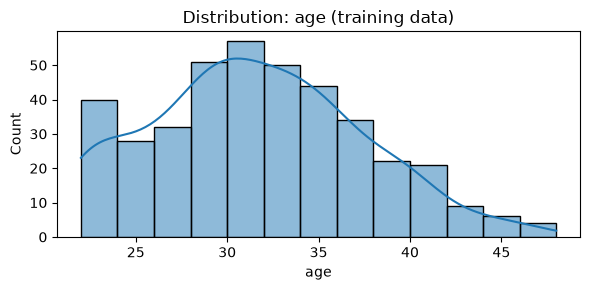

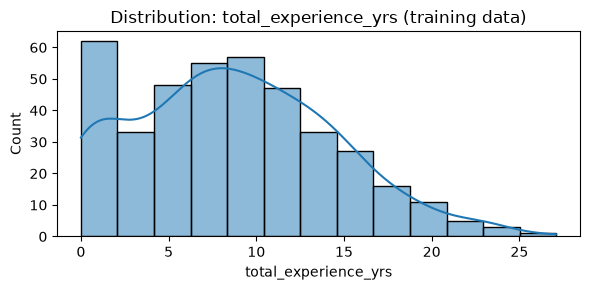

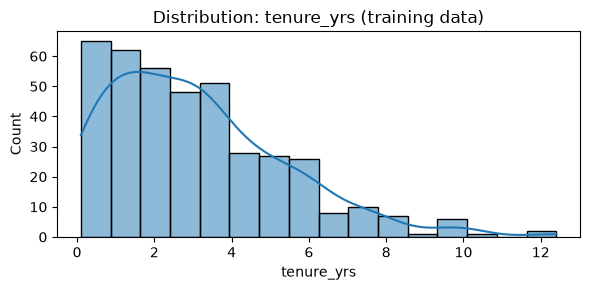

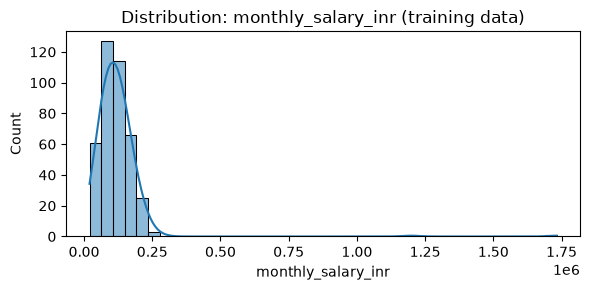

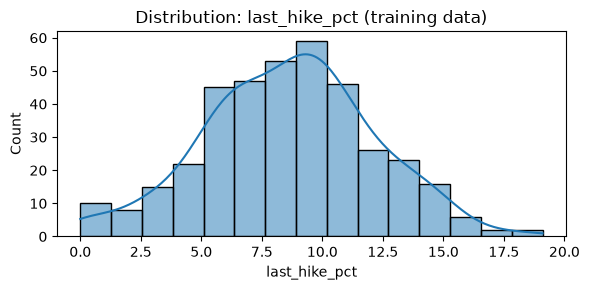

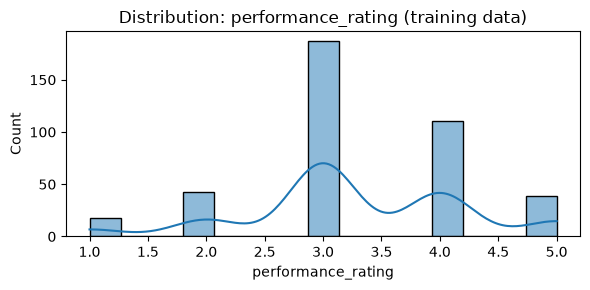

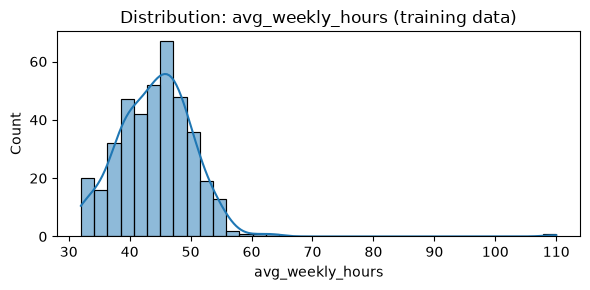

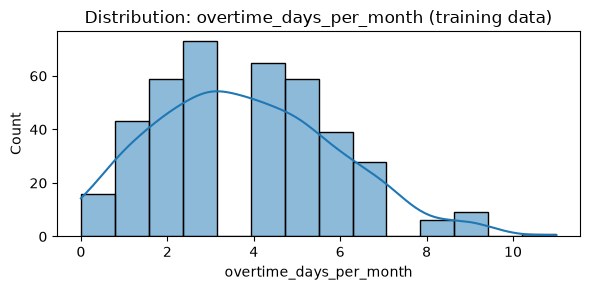

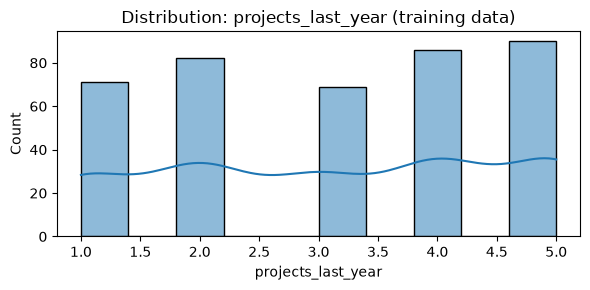

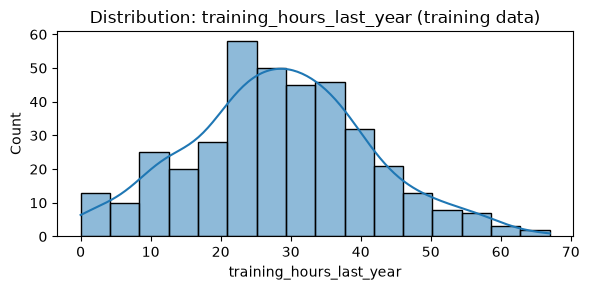

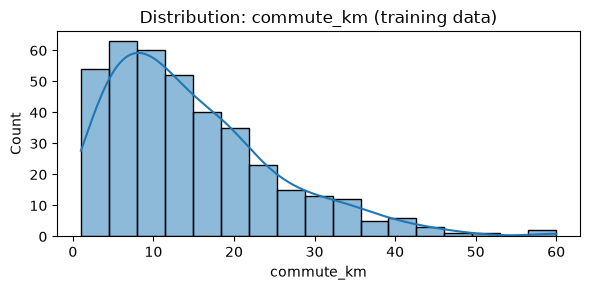

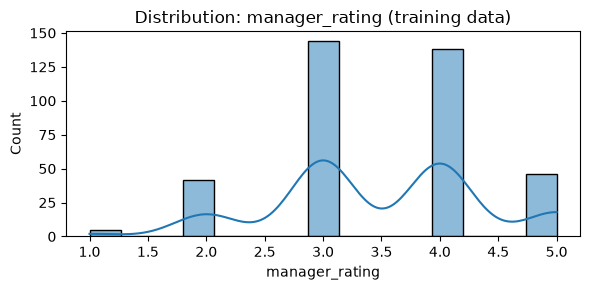

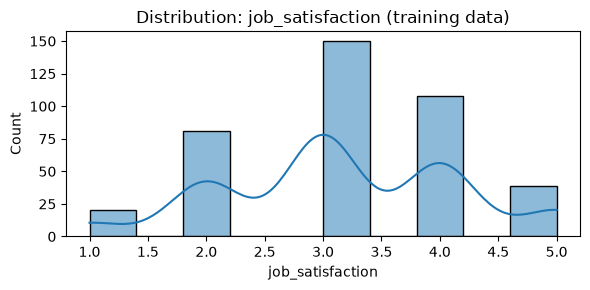

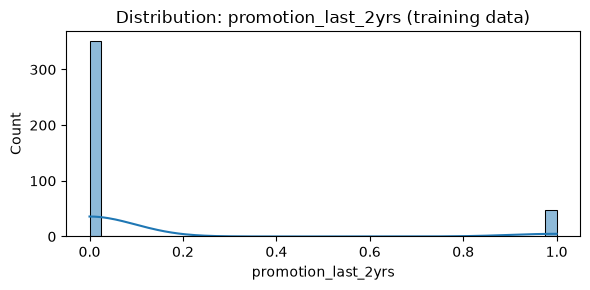

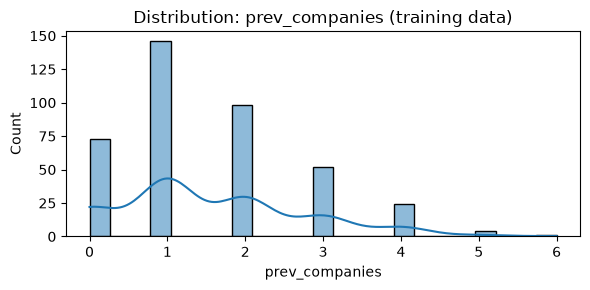

In [10]:
numeric_train = X_train.select_dtypes(include=["number"]).copy()
skew_table = pd.DataFrame({
    "skewness": numeric_train.skew(numeric_only=True),
    "mean": numeric_train.mean(),
    "median": numeric_train.median(),
    "min": numeric_train.min(),
    "max": numeric_train.max()
}).sort_values("skewness", key=lambda s: s.abs(), ascending=False)
display(skew_table)

def compare_transforms(series):
    s = pd.to_numeric(series, errors="coerce").dropna().astype(float)
    if len(s) < 3 or s.nunique() < 3:
        return {"raw_skew": np.nan, "log1p_skew": np.nan, "boxcox_skew": np.nan, "yeojohnson_skew": np.nan}
    result = {"raw_skew": float(s.skew())}
    # log1p only valid when all values > -1
    result["log1p_skew"] = float(np.log1p(s).skew()) if (s > -1).all() else np.nan
    # Box-Cox strictly positive only
    result["boxcox_skew"] = float(pd.Series(boxcox(s)[0]).skew()) if (s > 0).all() else np.nan
    try:
        yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(s.to_numpy().reshape(-1, 1)).ravel()
        result["yeojohnson_skew"] = float(pd.Series(yj).skew())
    except Exception:
        result["yeojohnson_skew"] = np.nan
    return result

transform_comparison = pd.DataFrame({c: compare_transforms(numeric_train[c]) for c in numeric_train.columns}).T
display(transform_comparison.sort_values("raw_skew", key=lambda s: s.abs(), ascending=False))

# Plot histograms for numeric columns. This is exploratory; do not infer causation from distributions.
for c in numeric_train.columns:
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.histplot(numeric_train[c].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution: {c} (training data)")
    plt.tight_layout()
    plt.show()


## Step 13 — VIF for numeric features

In [11]:
def calculate_vif(frame):
    num = frame.select_dtypes(include=["number"]).copy()
    if num.shape[1] < 2:
        return pd.DataFrame(columns=["feature", "VIF"])
    num = num.replace([np.inf, -np.inf], np.nan)
    num = num.fillna(num.median()).dropna(axis=1, how="all")
    # Remove constant columns; VIF is undefined for them.
    num = num.loc[:, num.nunique(dropna=True) > 1]
    if num.shape[1] < 2:
        return pd.DataFrame(columns=["feature", "VIF"])
    # Standardize for numerical stability; VIF is scale invariant.
    arr = StandardScaler().fit_transform(num)
    out = []
    for i, col in enumerate(num.columns):
        try:
            out.append((col, float(variance_inflation_factor(arr, i))))
        except Exception:
            out.append((col, np.inf))
    return pd.DataFrame(out, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)

vif_table = calculate_vif(X_train)
display(vif_table)
print("Interpretation guide: VIF < 5 usually modest; 5–10 investigate; >=10 high. VIF is only calculated for numeric features here.")


,feature,VIF
1,total_experience_yrs,29.093434
0,age,28.647331
3,monthly_salary_inr,1.374174
2,tenure_yrs,1.187955
12,job_satisfaction,1.163825
11,manager_rating,1.152967
7,overtime_days_per_month,1.145976
6,avg_weekly_hours,1.129487
13,promotion_last_2yrs,1.072722
9,training_hours_last_year,1.053772


Interpretation guide: VIF < 5 usually modest; 5–10 investigate; >=10 high. VIF is only calculated for numeric features here.


## Step 14 — Information Value (IV) table
IV is estimated using training labels only. Numeric features are binned; categorical features use observed categories. Very high IV can indicate leakage or overfitting, so investigate it rather than celebrating it.

In [12]:
def iv_strength(iv):
    if pd.isna(iv): return "Unavailable"
    if iv < 0.02: return "Useless"
    if iv < 0.10: return "Weak"
    if iv < 0.30: return "Medium"
    if iv < 0.50: return "Strong"
    return "Suspicious"

def calculate_iv_feature(x, y, max_bins=10):
    temp = pd.DataFrame({"x": x, "y": y}).dropna()
    if temp.empty or temp["y"].nunique() < 2:
        return np.nan
    # Bin numeric variables; categories remain as categories.
    if pd.api.types.is_numeric_dtype(temp["x"]) and temp["x"].nunique() > max_bins:
        try:
            temp["group"] = pd.qcut(temp["x"], q=max_bins, duplicates="drop")
        except Exception:
            temp["group"] = temp["x"].astype(str)
    else:
        temp["group"] = temp["x"].astype(str)
    tab = pd.crosstab(temp["group"], temp["y"])
    for cls in [0, 1]:
        if cls not in tab.columns: tab[cls] = 0
    # Small smoothing prevents division by zero.
    eps = 0.5
    dist_good = (tab[0] + eps) / (tab[0].sum() + eps * len(tab))
    dist_bad = (tab[1] + eps) / (tab[1].sum() + eps * len(tab))
    woe = np.log(dist_good / dist_bad)
    iv = ((dist_good - dist_bad) * woe).sum()
    return float(iv)

iv_rows = []
for c in X_train.columns:
    val = calculate_iv_feature(X_train[c], y_train.loc[X_train.index])
    iv_rows.append({"feature": c, "IV": val, "strength": iv_strength(val)})
iv_table = pd.DataFrame(iv_rows).sort_values("IV", ascending=False)
display(iv_table)


,feature,IV,strength
15,job_satisfaction,0.455835,Strong
6,last_hike_pct,0.352592,Strong
14,manager_rating,0.342614,Strong
17,prev_companies,0.269231,Medium
3,total_experience_yrs,0.238873,Medium
9,overtime_days_per_month,0.227906,Medium
8,avg_weekly_hours,0.151381,Medium
5,monthly_salary_inr,0.135672,Medium
10,projects_last_year,0.123884,Medium
4,tenure_yrs,0.122366,Medium


## Step 15 — Correlation and multicollinearity

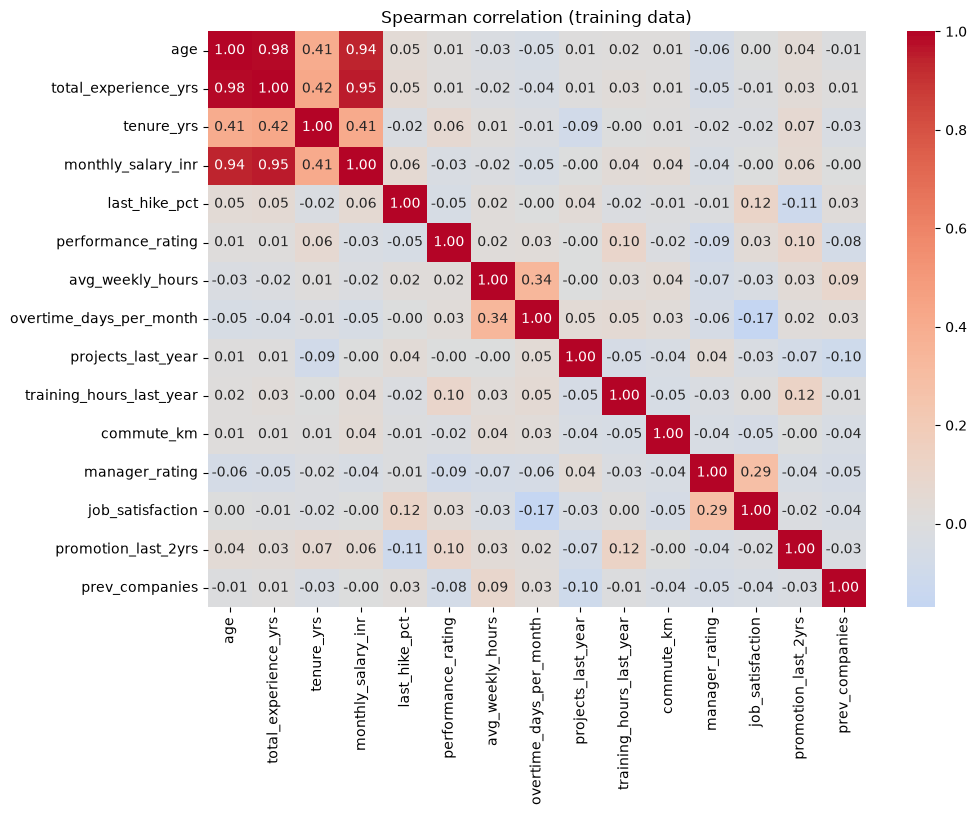

,feature_1,feature_2,spearman_corr
0,age,total_experience_yrs,0.981967
1,age,monthly_salary_inr,0.941065
2,total_experience_yrs,monthly_salary_inr,0.952727


In [13]:
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
if len(numeric_cols) >= 2:
    corr = X_train[numeric_cols].corr(method="spearman")
    plt.figure(figsize=(max(8, len(numeric_cols)*0.7), max(6, len(numeric_cols)*0.55)))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title("Spearman correlation (training data)")
    plt.tight_layout()
    plt.show()

    high_corr_pairs = []
    for i, c1 in enumerate(numeric_cols):
        for c2 in numeric_cols[i+1:]:
            val = corr.loc[c1, c2]
            if pd.notna(val) and abs(val) >= CORR_THRESHOLD:
                high_corr_pairs.append((c1, c2, float(val)))
    high_corr_table = pd.DataFrame(high_corr_pairs, columns=["feature_1", "feature_2", "spearman_corr"])
    display(high_corr_table)
else:
    corr = pd.DataFrame()
    high_corr_table = pd.DataFrame(columns=["feature_1", "feature_2", "spearman_corr"])


## Step 16–17 — Rank features and save multiple feature sets
Use IV as one screening signal, not as the only decision rule. Suspicious IV values are excluded from automatic ranking. VIF and correlation are diagnostics; do not drop a feature solely because of one statistic without checking business meaning.

In [14]:
iv_rank = iv_table.copy()
iv_rank["IV"] = pd.to_numeric(iv_rank["IV"], errors="coerce")
eligible = iv_rank[(iv_rank["IV"] >= IV_THRESHOLD) & (iv_rank["IV"] < MAX_IV_THRESHOLD)]["feature"].tolist()
# Keep features with no usable IV only if needed to fill the requested sizes; prefer higher IV.
ranked_features = iv_rank[iv_rank["IV"] < MAX_IV_THRESHOLD].sort_values("IV", ascending=False)["feature"].tolist()
ranked_features = [c for c in ranked_features if c in X_train.columns]
# If no feature meets the IV threshold, fall back to ranking all non-suspicious features.
if not ranked_features:
    ranked_features = X_train.columns.tolist()

feature_sets = {}
for n in [5, 8, 10, 15]:
    feature_sets[f"top_{n}"] = ranked_features[:min(n, len(ranked_features))]
feature_sets["iv_eligible"] = [c for c in eligible if c in X_train.columns]
if not feature_sets["iv_eligible"]:
    feature_sets["iv_eligible"] = ranked_features[:min(10, len(ranked_features))]

for name, cols in feature_sets.items():
    print(name, len(cols), cols)
    pd.concat([X_train[cols], y_train.rename(TARGET)], axis=1).to_csv(OUTPUT_DIR / f"train_{name}.csv", index=False)
    pd.concat([X_test[cols], y_test.rename(TARGET)], axis=1).to_csv(OUTPUT_DIR / f"test_{name}.csv", index=False)

with open(OUTPUT_DIR / "feature_sets.json", "w") as f:
    json.dump(feature_sets, f, indent=2)


top_5 5 ['job_satisfaction', 'last_hike_pct', 'manager_rating', 'prev_companies', 'total_experience_yrs']
top_8 8 ['job_satisfaction', 'last_hike_pct', 'manager_rating', 'prev_companies', 'total_experience_yrs', 'overtime_days_per_month', 'avg_weekly_hours', 'monthly_salary_inr']
top_10 10 ['job_satisfaction', 'last_hike_pct', 'manager_rating', 'prev_companies', 'total_experience_yrs', 'overtime_days_per_month', 'avg_weekly_hours', 'monthly_salary_inr', 'projects_last_year', 'tenure_yrs']
top_15 15 ['job_satisfaction', 'last_hike_pct', 'manager_rating', 'prev_companies', 'total_experience_yrs', 'overtime_days_per_month', 'avg_weekly_hours', 'monthly_salary_inr', 'projects_last_year', 'tenure_yrs', 'age', 'training_hours_last_year', 'commute_km', 'department', 'performance_rating']
iv_eligible 17 ['job_satisfaction', 'last_hike_pct', 'manager_rating', 'prev_companies', 'total_experience_yrs', 'overtime_days_per_month', 'avg_weekly_hours', 'monthly_salary_inr', 'projects_last_year', 'ten

# STEP 18: Train all models on all feature sets

In [15]:



import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Create folders
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define models
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        random_state=42,
        verbosity=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}


# Build preprocessing pipeline
def build_pipeline(features, model):

    numeric_features = [
        c for c in features
        if pd.api.types.is_numeric_dtype(X_train[c])
        or pd.api.types.is_bool_dtype(X_train[c])
    ]

    categorical_features = [
        c for c in features
        if c not in numeric_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", clone(model))
    ])

    return pipeline


# Store trained models and results
trained_models = {}
training_summary = []

# Train every model on every feature set
for feature_set_name, features in feature_sets.items():

    if not features:
        print(f"Skipping empty feature set: {feature_set_name}")
        continue

    Xtr = X_train[features].copy()
    Xte = X_test[features].copy()

    ytr = y_train.loc[Xtr.index]

    print(f"\nFeature Set: {feature_set_name}")
    print("=" * 60)

    for model_name, model in models.items():

        model_key = f"{feature_set_name}_{model_name}"

        try:
            pipeline = build_pipeline(features, model)

            # Train on original training data
            pipeline.fit(Xtr, ytr)

            # Save model and metadata
            model_path = MODEL_DIR / f"{model_key}.joblib"

            joblib.dump({
                "pipeline": pipeline,
                "features": features,
                "feature_set": feature_set_name,
                "model_name": model_name
            }, model_path)

            trained_models[model_key] = pipeline

            training_summary.append({
                "model_key": model_key,
                "feature_set": feature_set_name,
                "model": model_name,
                "number_of_features": len(features),
                "model_path": str(model_path)
            })

            print("Trained and saved:", model_key)

        except Exception as e:
            print(f"Error training {model_key}: {e}")


training_summary_df = pd.DataFrame(training_summary)

training_summary_df.to_csv(
    OUTPUT_DIR / "training_summary.csv",
    index=False
)

display(training_summary_df)

print("\nTotal successfully trained models:", len(trained_models))


Feature Set: top_5
Trained and saved: top_5_LogisticRegression
Trained and saved: top_5_RandomForest
Trained and saved: top_5_LightGBM
Trained and saved: top_5_XGBoost

Feature Set: top_8
Trained and saved: top_8_LogisticRegression
Trained and saved: top_8_RandomForest
Trained and saved: top_8_LightGBM
Trained and saved: top_8_XGBoost

Feature Set: top_10
Trained and saved: top_10_LogisticRegression
Trained and saved: top_10_RandomForest
Trained and saved: top_10_LightGBM
Trained and saved: top_10_XGBoost

Feature Set: top_15
Trained and saved: top_15_LogisticRegression
Trained and saved: top_15_RandomForest
Trained and saved: top_15_LightGBM
Trained and saved: top_15_XGBoost

Feature Set: iv_eligible
Trained and saved: iv_eligible_LogisticRegression
Trained and saved: iv_eligible_RandomForest
Trained and saved: iv_eligible_LightGBM
Trained and saved: iv_eligible_XGBoost


,model_key,feature_set,model,number_of_features,model_path
0,top_5_LogisticRegression,top_5,LogisticRegression,5,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
1,top_5_RandomForest,top_5,RandomForest,5,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
2,top_5_LightGBM,top_5,LightGBM,5,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
3,top_5_XGBoost,top_5,XGBoost,5,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
4,top_8_LogisticRegression,top_8,LogisticRegression,8,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
5,top_8_RandomForest,top_8,RandomForest,8,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
6,top_8_LightGBM,top_8,LightGBM,8,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
7,top_8_XGBoost,top_8,XGBoost,8,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
8,top_10_LogisticRegression,top_10,LogisticRegression,10,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...
9,top_10_RandomForest,top_10,RandomForest,10,/Users/riteshchaurasiya/Desktop/Hexaware_OA/sa...



Total successfully trained models: 20


# STEP 19: Calculate model performance metrics

In [16]:
# STEP 19: Evaluate all trained models

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

metrics_results = []

for model_key, pipeline in trained_models.items():

    # Get model metadata
    metadata = training_summary_df.loc[
        training_summary_df["model_key"] == model_key
    ].iloc[0]

    feature_set_name = metadata["feature_set"]

    # Get the exact features associated with this model
    features = feature_sets[feature_set_name]

    Xtr = X_train[features].copy()
    Xte = X_test[features].copy()

    ytr = y_train.loc[Xtr.index]
    yte = y_test.loc[Xte.index]

    # Verify the input feature count
    expected_features = pipeline.named_steps[
        "preprocessing"
    ].feature_names_in_ if hasattr(
        pipeline.named_steps["preprocessing"],
        "feature_names_in_"
    ) else None

    print(
        f"Evaluating {model_key}: "
        f"{len(features)} original features"
    )

    # Predict probabilities
    train_prob = pipeline.predict_proba(Xtr)[:, 1]
    test_prob = pipeline.predict_proba(Xte)[:, 1]

    # Predict classes
    train_pred = (train_prob >= 0.50).astype(int)
    test_pred = (test_prob >= 0.50).astype(int)

    # Calculate metrics
    for dataset_name, actual, predicted, probabilities in [
        ("Train", ytr, train_pred, train_prob),
        ("Test", yte, test_pred, test_prob)
    ]:

        metrics_results.append({
            "model_key": model_key,
            "feature_set": feature_set_name,
            "model": metadata["model"],
            "dataset": dataset_name,

            "Accuracy": accuracy_score(
                actual, predicted
            ),

            "Precision": precision_score(
                actual, predicted,
                zero_division=0
            ),

            "Recall": recall_score(
                actual, predicted,
                zero_division=0
            ),

            "AUC": (
                roc_auc_score(actual, probabilities)
                if actual.nunique() == 2
                else np.nan
            )
        })


metrics_df = pd.DataFrame(metrics_results)

display(
    metrics_df.sort_values(
        ["dataset", "AUC", "Recall"],
        ascending=[True, False, False]
    ).round(4)
)

metrics_df.to_csv(
    OUTPUT_DIR / "model_metrics.csv",
    index=False
)

print("\nMetrics saved successfully!")

Evaluating top_5_LogisticRegression: 5 original features
Evaluating top_5_RandomForest: 5 original features
Evaluating top_5_LightGBM: 5 original features
Evaluating top_5_XGBoost: 5 original features
Evaluating top_8_LogisticRegression: 8 original features
Evaluating top_8_RandomForest: 8 original features
Evaluating top_8_LightGBM: 8 original features
Evaluating top_8_XGBoost: 8 original features
Evaluating top_10_LogisticRegression: 10 original features
Evaluating top_10_RandomForest: 10 original features
Evaluating top_10_LightGBM: 10 original features
Evaluating top_10_XGBoost: 10 original features
Evaluating top_15_LogisticRegression: 15 original features
Evaluating top_15_RandomForest: 15 original features
Evaluating top_15_LightGBM: 15 original features
Evaluating top_15_XGBoost: 15 original features
Evaluating iv_eligible_LogisticRegression: 17 original features
Evaluating iv_eligible_RandomForest: 17 original features
Evaluating iv_eligible_LightGBM: 17 original features
Eval

,model_key,feature_set,model,dataset,Accuracy,Precision,Recall,AUC
9,top_8_LogisticRegression,top_8,LogisticRegression,Test,0.8200,0.6667,0.2000,0.8031
17,top_10_LogisticRegression,top_10,LogisticRegression,Test,0.7900,0.4000,0.1000,0.7912
3,top_5_RandomForest,top_5,RandomForest,Test,0.8200,0.6667,0.2000,0.7816
13,top_8_LightGBM,top_8,LightGBM,Test,0.7900,0.4545,0.2500,0.7806
15,top_8_XGBoost,top_8,XGBoost,Test,0.8000,0.5000,0.3000,0.7750
1,top_5_LogisticRegression,top_5,LogisticRegression,Test,0.8100,0.6000,0.1500,0.7750
5,top_5_LightGBM,top_5,LightGBM,Test,0.8000,0.5000,0.3000,0.7731
11,top_8_RandomForest,top_8,RandomForest,Test,0.8200,1.0000,0.1000,0.7731
7,top_5_XGBoost,top_5,XGBoost,Test,0.8200,0.5833,0.3500,0.7619
25,top_15_LogisticRegression,top_15,LogisticRegression,Test,0.8100,0.5714,0.2000,0.7512



Metrics saved successfully!


# STEP 20: Optuna hyperparameter tuning

In [ ]:


import optuna

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

optuna.logging.set_verbosity(optuna.logging.WARNING)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

optuna_results = []
best_tuned_models = {}


def create_tuned_model(model_name, trial):

    if model_name == "LogisticRegression":

        return LogisticRegression(
            C=trial.suggest_float(
                "C", 0.001, 100, log=True
            ),
            max_iter=3000,
            random_state=42
        )

    elif model_name == "RandomForest":

        return RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 100, 400
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            random_state=42,
            n_jobs=-1
        )

    elif model_name == "LightGBM":

        return LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 100, 400
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 10
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 40
            ),
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

    elif model_name == "XGBoost":

        return XGBClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 100, 400
            ),
            max_depth=trial.suggest_int(
                "max_depth", 2, 8
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),
            subsample=trial.suggest_float(
                "subsample", 0.7, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.7, 1.0
            ),
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

    raise ValueError(f"Unknown model: {model_name}")


for feature_set_name, features in feature_sets.items():

    if not features:
        continue

    Xtr = X_train[features].copy()
    ytr = y_train.loc[Xtr.index]

    for model_name in models:

        print(
            f"Tuning {model_name} with {feature_set_name}"
        )

        def objective(trial):

            model = create_tuned_model(
                model_name, trial
            )

            pipeline = build_pipeline(
                features, model
            )

            scores = cross_validate(
                pipeline,
                Xtr,
                ytr,
                cv=cv,
                scoring={
                    "recall": "recall",
                    "roc_auc": "roc_auc"
                },
                n_jobs=1,
                error_score="raise"
            )

            recall = scores["test_recall"].mean()
            auc = scores["test_roc_auc"].mean()

            trial.set_user_attr(
                "mean_recall", float(recall)
            )

            trial.set_user_attr(
                "mean_auc", float(auc)
            )

            return 0.5 * recall + 0.5 * auc


        study = optuna.create_study(
            direction="maximize",
            sampler=optuna.samplers.TPESampler(
                seed=42
            )
        )

        study.optimize(
            objective,
            n_trials=20,
            show_progress_bar=False
        )

        best_model = create_tuned_model(
            model_name,
            optuna.trial.FixedTrial(
                study.best_params
            )
        )

        tuned_pipeline = build_pipeline(
            features, best_model
        )

        # Refit on all training data
        tuned_pipeline.fit(Xtr, ytr)

        tuned_key = f"{feature_set_name}_{model_name}_Tuned"

        best_tuned_models[tuned_key] = tuned_pipeline

        # Save tuned model
        joblib.dump(
            {
                "pipeline": tuned_pipeline,
                "features": features,
                "feature_set": feature_set_name,
                "model_name": model_name,
                "best_params": study.best_params,
                "cv_recall": study.best_trial.user_attrs["mean_recall"],
                "cv_auc": study.best_trial.user_attrs["mean_auc"]
            },
            MODEL_DIR / f"{tuned_key}.joblib"
        )

        optuna_results.append({
            "model_key": tuned_key,
            "feature_set": feature_set_name,
            "model": model_name,
            "best_score": study.best_value,
            "cv_recall": study.best_trial.user_attrs["mean_recall"],
            "cv_auc": study.best_trial.user_attrs["mean_auc"],
            "best_params": json.dumps(study.best_params)
        })


optuna_results_df = pd.DataFrame(optuna_results)

display(
    optuna_results_df.sort_values(
        "best_score", ascending=False
    ).round(4)
)

optuna_results_df.to_csv(
    OUTPUT_DIR / "optuna_results.csv",
    index=False
)

print("Optuna tuning completed.")

Tuning LogisticRegression with top_5
Tuning RandomForest with top_5


# STEP 21 : Evaluation

In [ ]:
# STEP 21: Final Evaluation 

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)


def calculate_decile_ranking(y_true, probabilities):

    data = pd.DataFrame({
        "actual": np.asarray(y_true),
        "probability": np.asarray(probabilities)
    })

    # Rank employees from highest to lowest predicted attrition risk.
    data = data.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)

    if len(data) == 0:
        return np.nan, pd.DataFrame()

    # Divide employees into 10 approximately equal-sized deciles.
    data["decile"] = (
        np.floor(
            np.arange(len(data)) * 10 / len(data)
        ).astype(int) + 1
    )

    data["decile"] = data["decile"].clip(upper=10)

    total_positives = (data["actual"] == 1).sum()

    if total_positives == 0:
        return np.nan, pd.DataFrame()

    # Summarize attrition within each decile.
    summary = (
        data.groupby("decile")
        .agg(
            employees=("actual", "size"),
            attrition_cases=("actual", "sum"),
            mean_predicted_probability=("probability", "mean")
        )
        .reset_index()
    )

    # Calculate cumulative attrition capture.
    summary["cumulative_attrition_cases"] = (
        summary["attrition_cases"].cumsum()
    )

    summary["cumulative_attrition_capture"] = (
        summary["cumulative_attrition_cases"] / total_positives
    )

    # Find the first decile at which cumulative capture reaches 80%.
    matching = summary.loc[
        summary["cumulative_attrition_capture"] >= 0.80,
        "decile"
    ]

    decile_80 = (
        int(matching.iloc[0])
        if not matching.empty
        else np.nan
    )

    return decile_80, summary


def calculate_ks(y_true, probabilities):

    data = pd.DataFrame({
        "actual": np.asarray(y_true),
        "probability": np.asarray(probabilities)
    })

    positive_count = (data["actual"] == 1).sum()
    negative_count = (data["actual"] == 0).sum()

    if positive_count == 0 or negative_count == 0:
        return np.nan

    data = data.sort_values(
        "probability",
        ascending=False
    )

    data["cum_positive"] = (
        (data["actual"] == 1).cumsum() / positive_count
    )

    data["cum_negative"] = (
        (data["actual"] == 0).cumsum() / negative_count
    )

    return float(
        (
            data["cum_positive"] - data["cum_negative"]
        ).abs().max()
    )


# Store final evaluation results.
final_metrics = []

# Evaluate every tuned model.
for model_key, pipeline in best_tuned_models.items():

    metadata = optuna_results_df.loc[
        optuna_results_df["model_key"] == model_key
    ].iloc[0]

    feature_set_name = metadata["feature_set"]
    features = feature_sets[feature_set_name]

    Xtr = X_train[features]
    Xte = X_test[features]

    ytr = y_train.loc[Xtr.index]
    yte = y_test.loc[Xte.index]

    # Predicted attrition probabilities.
    train_prob = pipeline.predict_proba(Xtr)[:, 1]
    test_prob = pipeline.predict_proba(Xte)[:, 1]

    # Class predictions using a 0.50 threshold.
    train_pred = (train_prob >= 0.50).astype(int)
    test_pred = (test_prob >= 0.50).astype(int)

    # Calculate decile rankings separately for train and test.
    train_decile_80, train_decile_table = calculate_decile_ranking(
        ytr, train_prob
    )

    test_decile_80, test_decile_table = calculate_decile_ranking(
        yte, test_prob
    )

    # Display the result for every model.
    print(f"\nModel: {model_key}")
    print(
        f"Train: 80% attrition capture reached by decile "
        f"{train_decile_80}"
    )
    print(
        f"Test: 80% attrition capture reached by decile "
        f"{test_decile_80}"
    )

    # Save decile tables separately for detailed analysis.
    if not train_decile_table.empty:
        train_decile_table.to_csv(
            OUTPUT_DIR / f"{model_key}_train_deciles.csv",
            index=False
        )

    if not test_decile_table.empty:
        test_decile_table.to_csv(
            OUTPUT_DIR / f"{model_key}_test_deciles.csv",
            index=False
        )

    # Calculate metrics for both datasets.
    for dataset_name, actual, predicted, probabilities in [
        ("Train", ytr, train_pred, train_prob),
        ("Test", yte, test_pred, test_prob)
    ]:

        # Associate the correct decile result with each dataset.
        decile_80 = (
            train_decile_80
            if dataset_name == "Train"
            else test_decile_80
        )

        final_metrics.append({
            "model_key": model_key,
            "feature_set": feature_set_name,
            "model": metadata["model"],
            "dataset": dataset_name,

            "Accuracy": accuracy_score(
                actual, predicted
            ),

            "Precision": precision_score(
                actual, predicted,
                zero_division=0
            ),

            "Recall": recall_score(
                actual, predicted,
                zero_division=0
            ),

            "AUC": (
                roc_auc_score(actual, probabilities)
                if actual.nunique() == 2
                else np.nan
            ),

            "KS": calculate_ks(
                actual, probabilities
            ),

            "Decile_for_80pct_Attrition_Capture": decile_80
        })


# Convert results to a DataFrame.
final_metrics_df = pd.DataFrame(final_metrics)

# Display results.
display(
    final_metrics_df.sort_values(
        ["dataset", "AUC", "Recall"],
        ascending=[True, False, False]
    ).round(4)
)

# Save final performance metrics.
final_metrics_df.to_csv(
    OUTPUT_DIR / "final_train_test_metrics.csv",
    index=False
)

print("\nFinal evaluation completed successfully!")
print("Metrics saved to:", OUTPUT_DIR / "final_train_test_metrics.csv")


Model: top_5_LogisticRegression_Tuned
Train: 80% attrition capture reached by decile 5
Test: 80% attrition capture reached by decile 5

Model: top_5_RandomForest_Tuned
Train: 80% attrition capture reached by decile 2
Test: 80% attrition capture reached by decile 5

Model: top_5_LightGBM_Tuned
Train: 80% attrition capture reached by decile 2
Test: 80% attrition capture reached by decile 5

Model: top_5_XGBoost_Tuned
Train: 80% attrition capture reached by decile 2
Test: 80% attrition capture reached by decile 5

Model: top_8_LogisticRegression_Tuned
Train: 80% attrition capture reached by decile 5
Test: 80% attrition capture reached by decile 5

Model: top_8_RandomForest_Tuned
Train: 80% attrition capture reached by decile 2
Test: 80% attrition capture reached by decile 5

Model: top_8_LightGBM_Tuned
Train: 80% attrition capture reached by decile 2
Test: 80% attrition capture reached by decile 5

Model: top_8_XGBoost_Tuned
Train: 80% attrition capture reached by decile 3
Test: 80% attr

,model_key,feature_set,model,dataset,Accuracy,Precision,Recall,AUC,KS,Decile_for_80pct_Attrition_Capture
9,top_8_LogisticRegression_Tuned,top_8,LogisticRegression,Test,0.8200,0.6667,0.2000,0.8025,0.5000,5
17,top_10_LogisticRegression_Tuned,top_10,LogisticRegression,Test,0.7900,0.4000,0.1000,0.7912,0.4875,6
13,top_8_LightGBM_Tuned,top_8,LightGBM,Test,0.8100,0.6000,0.1500,0.7906,0.5000,5
15,top_8_XGBoost_Tuned,top_8,XGBoost,Test,0.8200,1.0000,0.1000,0.7837,0.4625,5
3,top_5_RandomForest_Tuned,top_5,RandomForest,Test,0.8200,0.6667,0.2000,0.7797,0.4750,5
1,top_5_LogisticRegression_Tuned,top_5,LogisticRegression,Test,0.8100,0.6000,0.1500,0.7750,0.4625,5
11,top_8_RandomForest_Tuned,top_8,RandomForest,Test,0.8000,0.5000,0.0500,0.7737,0.5125,5
5,top_5_LightGBM_Tuned,top_5,LightGBM,Test,0.8100,0.5455,0.3000,0.7594,0.3875,5
7,top_5_XGBoost_Tuned,top_5,XGBoost,Test,0.7900,0.4444,0.2000,0.7544,0.4750,5
25,top_15_LogisticRegression_Tuned,top_15,LogisticRegression,Test,0.8100,0.6000,0.1500,0.7406,0.3875,5



Final evaluation completed successfully!
Metrics saved to: outputs/final_train_test_metrics.csv
